1.Connexion au drive

In [138]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


2.Lecture d'un fichier CSV

In [139]:
import pandas as pds
dataset = pds.read_csv('/water_potability.csv')
dataset.head()


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


3. Détection et suppression des doublons

In [140]:
doublons= dataset.duplicated()
doublons

,0
0,False
1,False
2,False
3,False
4,False
...,...
3271,False
3272,False
3273,False
3274,False


In [141]:
print(doublons.sum())

0


In [142]:
dataset_sans_doublons = dataset.drop_duplicates()
dataset_sans_doublons

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0
...,...,...,...,...,...,...,...,...,...,...
3271,4.668102,193.681735,47580.991603,7.166639,359.948574,526.424171,13.894419,66.687695,4.435821,1
3272,7.808856,193.553212,17329.802160,8.061362,NaN,392.449580,19.903225,NaN,2.798243,1
3273,9.419510,175.762646,33155.578218,7.350233,NaN,432.044783,11.039070,69.845400,3.298875,1
3274,5.126763,230.603758,11983.869376,6.303357,NaN,402.883113,11.168946,77.488213,4.708658,1


4.La gestion des valeurs manquantes

4.1 La distribution des données pour la colonne Sulfate

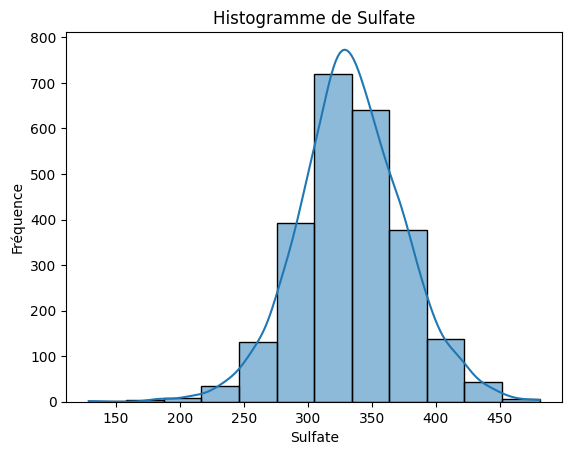

In [143]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(data=dataset, x='Sulfate', bins=12, kde=True)
plt.xlabel('Sulfate')
plt.ylabel('Fréquence')
plt.title('Histogramme de Sulfate')
plt.show()

4.2 Analyse statistique descriptive

In [144]:
dataset.describe()


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
count,2785.000000,3276.000000,3276.000000,3276.000000,2495.000000,3276.000000,3276.000000,3114.000000,3276.000000,3276.000000
mean,7.080795,196.369496,22014.092526,7.122277,333.775777,426.205111,14.284970,66.396293,3.966786,0.390110
std,1.594320,32.879761,8768.570828,1.583085,41.416840,80.824064,3.308162,16.175008,0.780382,0.487849
min,0.000000,47.432000,320.942611,0.352000,129.000000,181.483754,2.200000,0.738000,1.450000,0.000000
25%,6.093092,176.850538,15666.690297,6.127421,307.699498,365.734414,12.065801,55.844536,3.439711,0.000000
50%,7.036752,196.967627,20927.833607,7.130299,333.073546,421.884968,14.218338,66.622485,3.955028,0.000000
75%,8.062066,216.667456,27332.762127,8.114887,359.950170,481.792304,16.557652,77.337473,4.500320,1.000000
max,14.000000,323.124000,61227.196008,13.127000,481.030642,753.342620,28.300000,124.000000,6.739000,1.000000


4.3 Matrice de corrélation

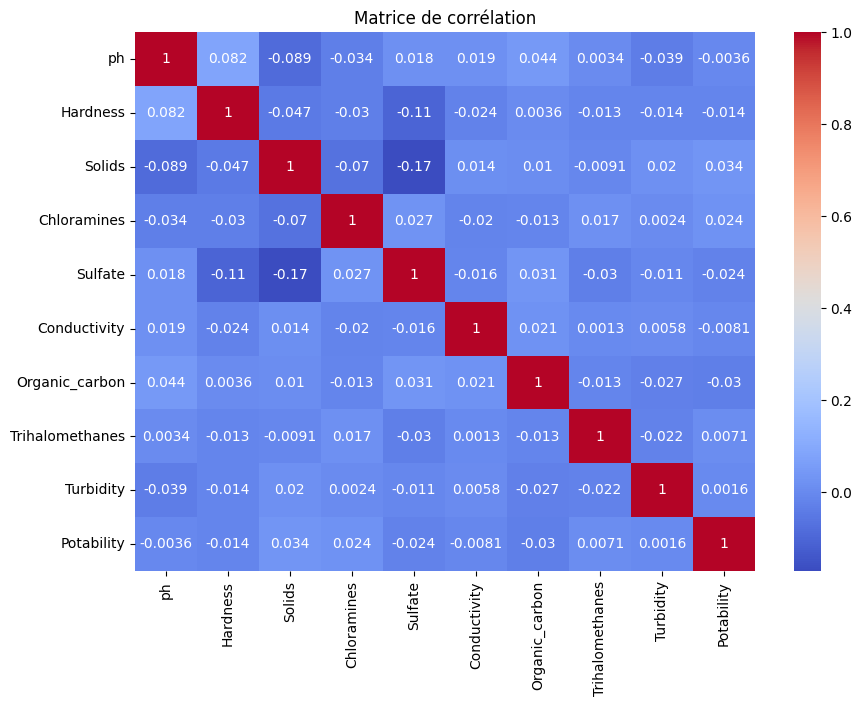

In [145]:
plt.figure(figsize=(10,7))
sns.heatmap(dataset.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.title("Matrice de corrélation")
plt.show()

4.4 Boxplot de sulfate (Détection des valeurs aberrantes)

Skewness : -0.036


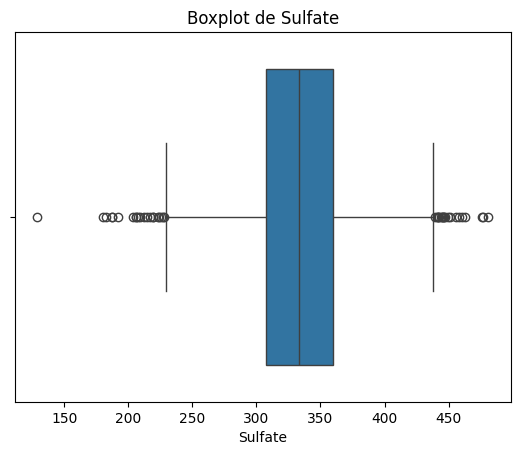

In [146]:
print('Skewness :', round(dataset['Sulfate'].skew(), 3))
sns.boxplot(x=dataset['Sulfate'])
plt.title('Boxplot de Sulfate')
plt.show()

In [147]:
dataset.isnull().sum()

,0
ph,491
Hardness,0
Solids,0
Chloramines,0
Sulfate,781
Conductivity,0
Organic_carbon,0
Trihalomethanes,162
Turbidity,0
Potability,0


5. Visualisation des valeurs manquantes

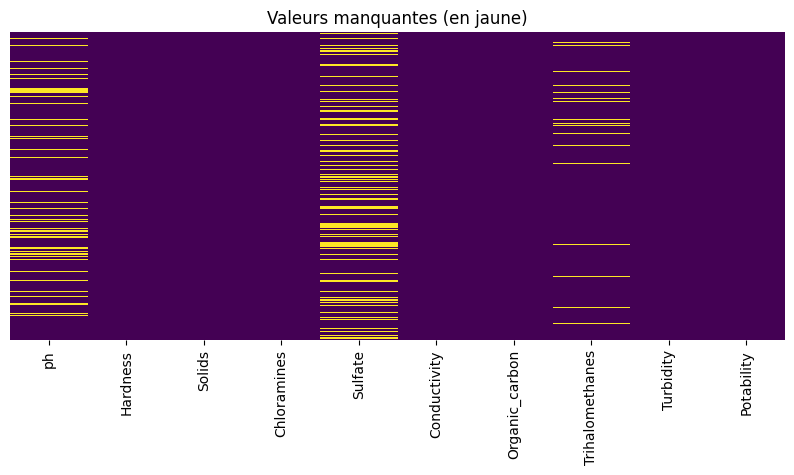

In [148]:
plt.figure(figsize=(10, 4))
sns.heatmap(dataset.isnull(), cbar=False, yticklabels=False, cmap='viridis')
plt.title('Valeurs manquantes (en jaune)')
plt.show()

6.Suppression

6.1 Supprimer les lignes qui contiennent des valeurs manquantes

In [149]:
ds=dataset.dropna()
ds

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0
5,5.584087,188.313324,28748.687739,7.544869,326.678363,280.467916,8.399735,54.917862,2.559708,0
6,10.223862,248.071735,28749.716544,7.513408,393.663396,283.651634,13.789695,84.603556,2.672989,0
7,8.635849,203.361523,13672.091764,4.563009,303.309771,474.607645,12.363817,62.798309,4.401425,0
...,...,...,...,...,...,...,...,...,...,...
3267,8.989900,215.047358,15921.412018,6.297312,312.931022,390.410231,9.899115,55.069304,4.613843,1
3268,6.702547,207.321086,17246.920347,7.708117,304.510230,329.266002,16.217303,28.878601,3.442983,1
3269,11.491011,94.812545,37188.826022,9.263166,258.930600,439.893618,16.172755,41.558501,4.369264,1
3270,6.069616,186.659040,26138.780191,7.747547,345.700257,415.886955,12.067620,60.419921,3.669712,1


In [150]:
ds.isnull().sum()

,0
ph,0
Hardness,0
Solids,0
Chloramines,0
Sulfate,0
Conductivity,0
Organic_carbon,0
Trihalomethanes,0
Turbidity,0
Potability,0


6.2 Supprimer les colonnes qui contiennent des valeurs manquantes



In [151]:
ds=dataset.dropna(axis=1)
ds

,Hardness,Solids,Chloramines,Conductivity,Organic_carbon,Turbidity,Potability
0,204.890455,20791.318981,7.300212,564.308654,10.379783,2.963135,0
1,129.422921,18630.057858,6.635246,592.885359,15.180013,4.500656,0
2,224.236259,19909.541732,9.275884,418.606213,16.868637,3.055934,0
3,214.373394,22018.417441,8.059332,363.266516,18.436524,4.628771,0
4,181.101509,17978.986339,6.546600,398.410813,11.558279,4.075075,0
...,...,...,...,...,...,...,...
3271,193.681735,47580.991603,7.166639,526.424171,13.894419,4.435821,1
3272,193.553212,17329.802160,8.061362,392.449580,19.903225,2.798243,1
3273,175.762646,33155.578218,7.350233,432.044783,11.039070,3.298875,1
3274,230.603758,11983.869376,6.303357,402.883113,11.168946,4.708658,1


In [152]:
ds=dataset.dropna(subset=['Sulfate'])
ds

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0
5,5.584087,188.313324,28748.687739,7.544869,326.678363,280.467916,8.399735,54.917862,2.559708,0
6,10.223862,248.071735,28749.716544,7.513408,393.663396,283.651634,13.789695,84.603556,2.672989,0
...,...,...,...,...,...,...,...,...,...,...
3267,8.989900,215.047358,15921.412018,6.297312,312.931022,390.410231,9.899115,55.069304,4.613843,1
3268,6.702547,207.321086,17246.920347,7.708117,304.510230,329.266002,16.217303,28.878601,3.442983,1
3269,11.491011,94.812545,37188.826022,9.263166,258.930600,439.893618,16.172755,41.558501,4.369264,1
3270,6.069616,186.659040,26138.780191,7.747547,345.700257,415.886955,12.067620,60.419921,3.669712,1


In [153]:
ds.isnull().sum()

,0
ph,379
Hardness,0
Solids,0
Chloramines,0
Sulfate,0
Conductivity,0
Organic_carbon,0
Trihalomethanes,122
Turbidity,0
Potability,0


7. Remplir les valeurs manquantes

7.1  Remplir par la moyenne

In [154]:
print(dataset['Sulfate'].mean())

333.7757766108135


In [155]:
ds=dataset.copy()
ds['Sulfate']=ds['Sulfate'].fillna(ds['Sulfate'].mean())
ds

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,333.775777,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,333.775777,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0
...,...,...,...,...,...,...,...,...,...,...
3271,4.668102,193.681735,47580.991603,7.166639,359.948574,526.424171,13.894419,66.687695,4.435821,1
3272,7.808856,193.553212,17329.802160,8.061362,333.775777,392.449580,19.903225,NaN,2.798243,1
3273,9.419510,175.762646,33155.578218,7.350233,333.775777,432.044783,11.039070,69.845400,3.298875,1
3274,5.126763,230.603758,11983.869376,6.303357,333.775777,402.883113,11.168946,77.488213,4.708658,1


In [156]:
ds.isnull().sum()

,0
ph,491
Hardness,0
Solids,0
Chloramines,0
Sulfate,0
Conductivity,0
Organic_carbon,0
Trihalomethanes,162
Turbidity,0
Potability,0


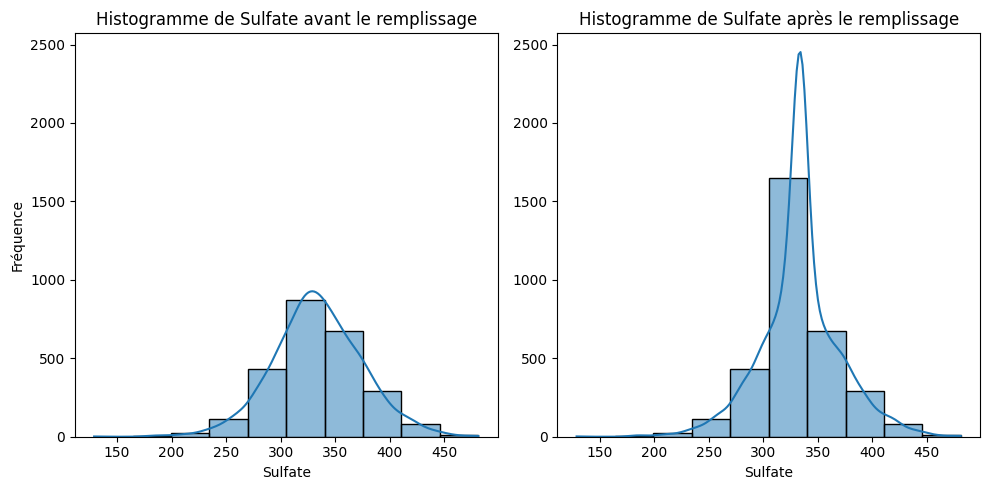

In [157]:
import matplotlib.pyplot as plt
import seaborn as sns
# Créer une figure avec deux sous-graphiques côte à côte
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5), sharex=True, sharey=True)  # 1 ligne, 2 colonnes

# Tracer le premier histogramme sur le premier sous-graphique
sns.histplot(dataset['Sulfate'], bins=10, ax=ax1,kde='true')
ax1.set_xlabel('Sulfate')
ax1.set_ylabel('Fréquence')
ax1.set_title('Histogramme de Sulfate avant le remplissage')

# Tracer le deuxième histogramme sur le deuxième sous-graphique
sns.histplot(ds['Sulfate'], bins=10, ax=ax2,kde='true')
ax2.set_xlabel('Sulfate')
ax2.set_ylabel('Fréquence')
ax2.set_title('Histogramme de Sulfate après le remplissage')

# Répéter la graduation pour les ordonnées sur la deuxième figure
ax2.tick_params(axis='y', labelleft=True)

# Ajuster l'espacement entre les sous-graphiques
plt.tight_layout()

# Afficher la figure
plt.show()

7.2  Remplir par la mediane

In [158]:
print(dataset['Sulfate'].median())

333.073545745888


In [159]:
ds=dataset.copy()
ds['Sulfate']=ds['Sulfate'].fillna(ds['Sulfate'].median())
ds

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,333.073546,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,333.073546,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0
...,...,...,...,...,...,...,...,...,...,...
3271,4.668102,193.681735,47580.991603,7.166639,359.948574,526.424171,13.894419,66.687695,4.435821,1
3272,7.808856,193.553212,17329.802160,8.061362,333.073546,392.449580,19.903225,NaN,2.798243,1
3273,9.419510,175.762646,33155.578218,7.350233,333.073546,432.044783,11.039070,69.845400,3.298875,1
3274,5.126763,230.603758,11983.869376,6.303357,333.073546,402.883113,11.168946,77.488213,4.708658,1


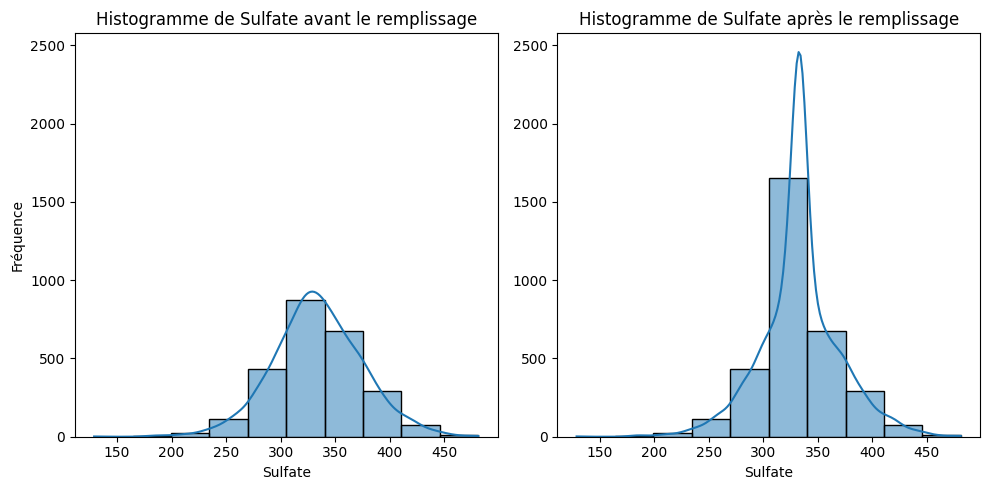

In [160]:
import matplotlib.pyplot as plt
import seaborn as sns
# Créer une figure avec deux sous-graphiques côte à côte
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5), sharex=True, sharey=True)  # 1 ligne, 2 colonnes

# Tracer le premier histogramme sur le premier sous-graphique
sns.histplot(dataset['Sulfate'], bins=10, ax=ax1,kde='true')
ax1.set_xlabel('Sulfate')
ax1.set_ylabel('Fréquence')
ax1.set_title('Histogramme de Sulfate avant le remplissage')

# Tracer le deuxième histogramme sur le deuxième sous-graphique
sns.histplot(ds['Sulfate'], bins=10, ax=ax2,kde='true')
ax2.set_xlabel('Sulfate')
ax2.set_ylabel('Fréquence')
ax2.set_title('Histogramme de Sulfate après le remplissage')

# Répéter la graduation pour les ordonnées sur la deuxième figure
ax2.tick_params(axis='y', labelleft=True)

# Ajuster l'espacement entre les sous-graphiques
plt.tight_layout()

# Afficher la figure
plt.show()

7.3  Remplir par la la valeur la plus fréquente

In [161]:
ds=dataset.copy()
ds['Sulfate']=ds['Sulfate'].fillna(ds['Sulfate'].mode()[0])
ds['Sulfate'].mode()

,Sulfate
0,129.0


In [162]:
ds = dataset.copy()
ds['Sulfate'] = ds['Sulfate'].fillna(ds['Sulfate'].mode()[0])
ds

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,129.000000,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,129.000000,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0
...,...,...,...,...,...,...,...,...,...,...
3271,4.668102,193.681735,47580.991603,7.166639,359.948574,526.424171,13.894419,66.687695,4.435821,1
3272,7.808856,193.553212,17329.802160,8.061362,129.000000,392.449580,19.903225,NaN,2.798243,1
3273,9.419510,175.762646,33155.578218,7.350233,129.000000,432.044783,11.039070,69.845400,3.298875,1
3274,5.126763,230.603758,11983.869376,6.303357,129.000000,402.883113,11.168946,77.488213,4.708658,1


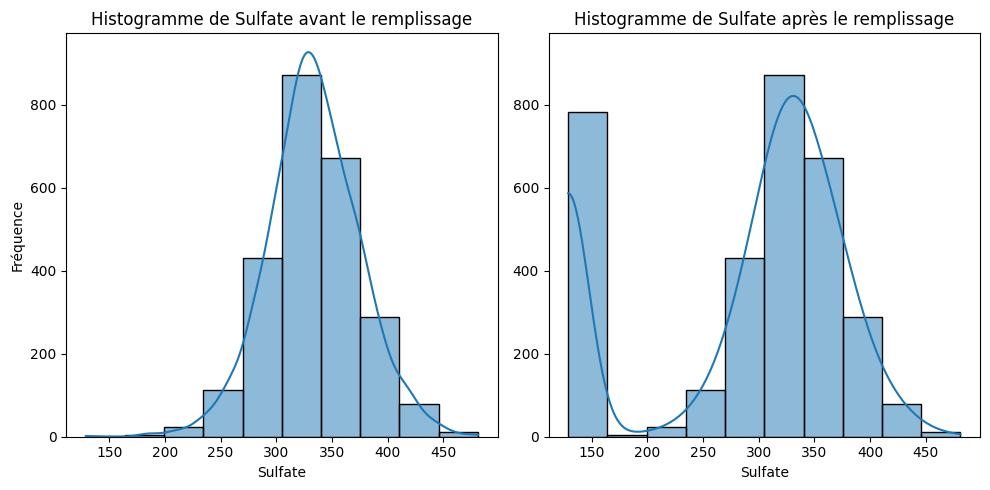

In [163]:
import matplotlib.pyplot as plt
import seaborn as sns
# Créer une figure avec deux sous-graphiques côte à côte
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5), sharex=True, sharey=True)  # 1 ligne, 2 colonnes

# Tracer le premier histogramme sur le premier sous-graphique
sns.histplot(dataset['Sulfate'], bins=10, ax=ax1,kde='true')
ax1.set_xlabel('Sulfate')
ax1.set_ylabel('Fréquence')
ax1.set_title('Histogramme de Sulfate avant le remplissage')

# Tracer le deuxième histogramme sur le deuxième sous-graphique
sns.histplot(ds['Sulfate'], bins=10, ax=ax2,kde='true')
ax2.set_xlabel('Sulfate')
ax2.set_ylabel('Fréquence')
ax2.set_title('Histogramme de Sulfate après le remplissage')

# Répéter la graduation pour les ordonnées sur la deuxième figure
ax2.tick_params(axis='y', labelleft=True)

# Ajuster l'espacement entre les sous-graphiques
plt.tight_layout()

# Afficher la figure
plt.show()

7.4 Remplir par une constante

In [164]:
ds = dataset.copy()
ds['Sulfate'] = ds['Sulfate'].fillna(100)
ds

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,100.000000,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,100.000000,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0
...,...,...,...,...,...,...,...,...,...,...
3271,4.668102,193.681735,47580.991603,7.166639,359.948574,526.424171,13.894419,66.687695,4.435821,1
3272,7.808856,193.553212,17329.802160,8.061362,100.000000,392.449580,19.903225,NaN,2.798243,1
3273,9.419510,175.762646,33155.578218,7.350233,100.000000,432.044783,11.039070,69.845400,3.298875,1
3274,5.126763,230.603758,11983.869376,6.303357,100.000000,402.883113,11.168946,77.488213,4.708658,1


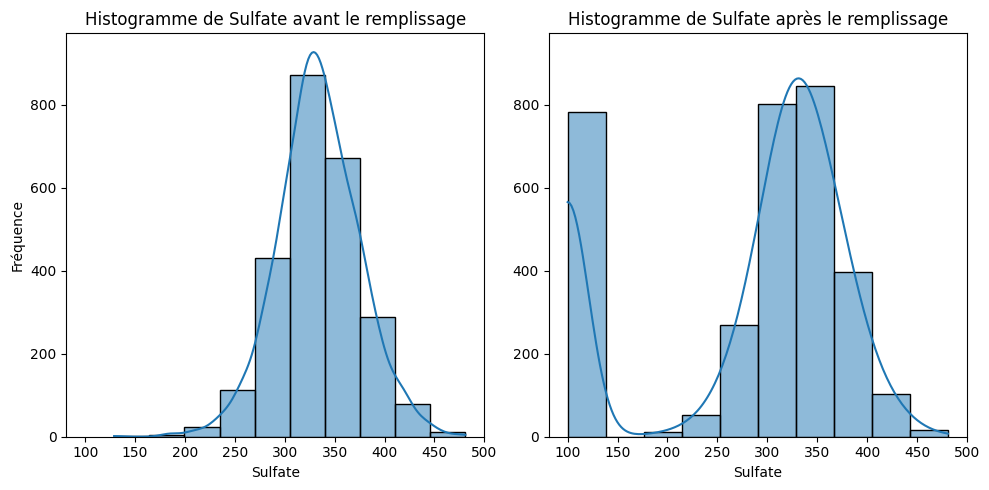

In [165]:
import matplotlib.pyplot as plt
import seaborn as sns
# Créer une figure avec deux sous-graphiques côte à côte
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5), sharex=True, sharey=True)  # 1 ligne, 2 colonnes

# Tracer le premier histogramme sur le premier sous-graphique
sns.histplot(dataset['Sulfate'], bins=10, ax=ax1,kde='true')
ax1.set_xlabel('Sulfate')
ax1.set_ylabel('Fréquence')
ax1.set_title('Histogramme de Sulfate avant le remplissage')

# Tracer le deuxième histogramme sur le deuxième sous-graphique
sns.histplot(ds['Sulfate'], bins=10, ax=ax2,kde='true')
ax2.set_xlabel('Sulfate')
ax2.set_ylabel('Fréquence')
ax2.set_title('Histogramme de Sulfate après le remplissage')

# Répéter la graduation pour les ordonnées sur la deuxième figure
ax2.tick_params(axis='y', labelleft=True)

# Ajuster l'espacement entre les sous-graphiques
plt.tight_layout()

# Afficher la figure
plt.show()

7.5 Imputation par la valeur suivante / précédente

In [166]:
ds = dataset.copy()
ds['Sulfate'] = ds['Sulfate'].bfill()
ds

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,356.886136,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,356.886136,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0
...,...,...,...,...,...,...,...,...,...,...
3271,4.668102,193.681735,47580.991603,7.166639,359.948574,526.424171,13.894419,66.687695,4.435821,1
3272,7.808856,193.553212,17329.802160,8.061362,NaN,392.449580,19.903225,NaN,2.798243,1
3273,9.419510,175.762646,33155.578218,7.350233,NaN,432.044783,11.039070,69.845400,3.298875,1
3274,5.126763,230.603758,11983.869376,6.303357,NaN,402.883113,11.168946,77.488213,4.708658,1


 Remarque: bfill laisse 4 valeurs manquantes à la fin de la colonne il n'y a pas de valeur suivante

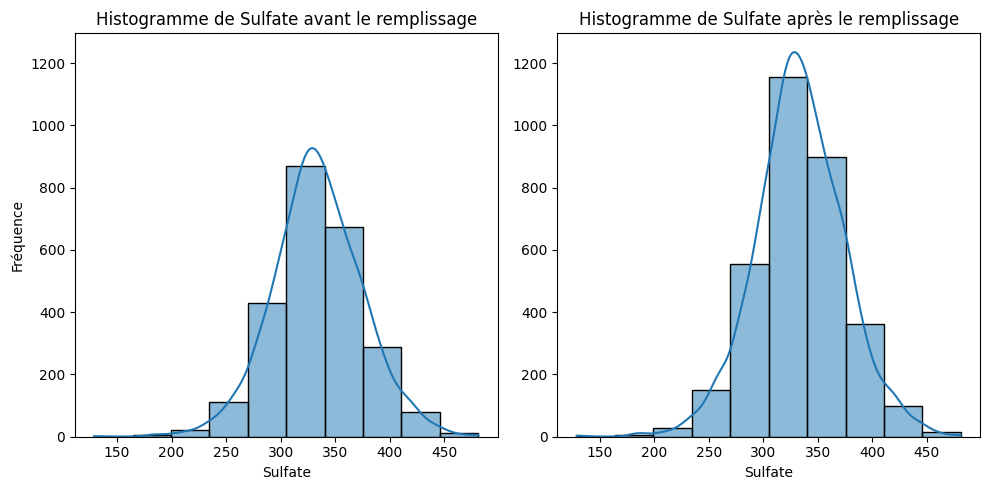

In [167]:
import matplotlib.pyplot as plt
import seaborn as sns
# Créer une figure avec deux sous-graphiques côte à côte
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5), sharex=True, sharey=True)  # 1 ligne, 2 colonnes

# Tracer le premier histogramme sur le premier sous-graphique
sns.histplot(dataset['Sulfate'], bins=10, ax=ax1,kde='true')
ax1.set_xlabel('Sulfate')
ax1.set_ylabel('Fréquence')
ax1.set_title('Histogramme de Sulfate avant le remplissage')

# Tracer le deuxième histogramme sur le deuxième sous-graphique
sns.histplot(ds['Sulfate'], bins=10, ax=ax2,kde='true')
ax2.set_xlabel('Sulfate')
ax2.set_ylabel('Fréquence')
ax2.set_title('Histogramme de Sulfate après le remplissage')

# Répéter la graduation pour les ordonnées sur la deuxième figure
ax2.tick_params(axis='y', labelleft=True)

# Ajuster l'espacement entre les sous-graphiques
plt.tight_layout()

# Afficher la figure
plt.show()

In [168]:
ds = dataset.copy()
ds['Sulfate'] = ds['Sulfate'].ffill()
ds

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,368.516441,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,368.516441,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0
...,...,...,...,...,...,...,...,...,...,...
3271,4.668102,193.681735,47580.991603,7.166639,359.948574,526.424171,13.894419,66.687695,4.435821,1
3272,7.808856,193.553212,17329.802160,8.061362,359.948574,392.449580,19.903225,NaN,2.798243,1
3273,9.419510,175.762646,33155.578218,7.350233,359.948574,432.044783,11.039070,69.845400,3.298875,1
3274,5.126763,230.603758,11983.869376,6.303357,359.948574,402.883113,11.168946,77.488213,4.708658,1


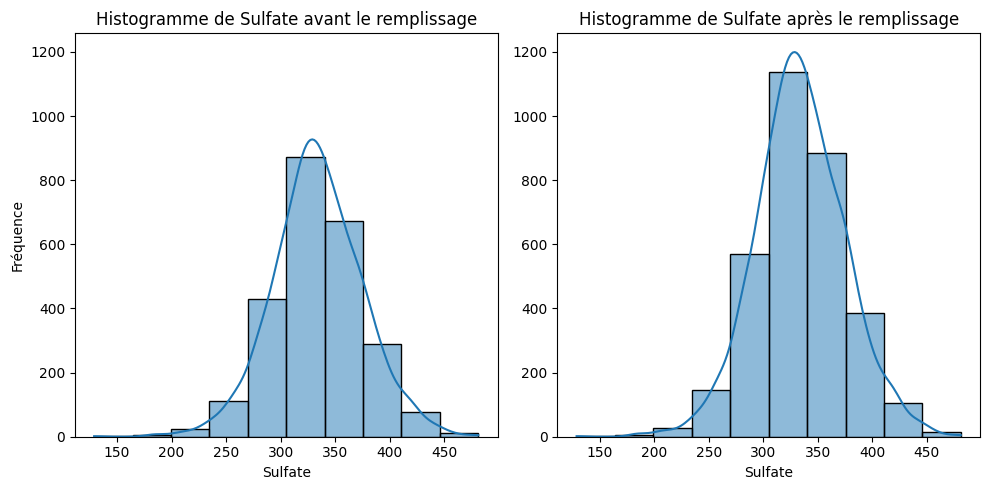

In [169]:
import matplotlib.pyplot as plt
import seaborn as sns
# Créer une figure avec deux sous-graphiques côte à côte
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5), sharex=True, sharey=True)  # 1 ligne, 2 colonnes

# Tracer le premier histogramme sur le premier sous-graphique
sns.histplot(dataset['Sulfate'], bins=10, ax=ax1,kde='true')
ax1.set_xlabel('Sulfate')
ax1.set_ylabel('Fréquence')
ax1.set_title('Histogramme de Sulfate avant le remplissage')

# Tracer le deuxième histogramme sur le deuxième sous-graphique
sns.histplot(ds['Sulfate'], bins=10, ax=ax2,kde='true')
ax2.set_xlabel('Sulfate')
ax2.set_ylabel('Fréquence')
ax2.set_title('Histogramme de Sulfate après le remplissage')

# Répéter la graduation pour les ordonnées sur la deuxième figure
ax2.tick_params(axis='y', labelleft=True)

# Ajuster l'espacement entre les sous-graphiques
plt.tight_layout()

# Afficher la figure
plt.show()

 7.6 Imputation par interpolation linéaire

In [170]:
ds = dataset.copy()
ds['Sulfate'] = ds['Sulfate'].interpolate(method='linear')
ds

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,364.639673,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,360.762904,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0
...,...,...,...,...,...,...,...,...,...,...
3271,4.668102,193.681735,47580.991603,7.166639,359.948574,526.424171,13.894419,66.687695,4.435821,1
3272,7.808856,193.553212,17329.802160,8.061362,359.948574,392.449580,19.903225,NaN,2.798243,1
3273,9.419510,175.762646,33155.578218,7.350233,359.948574,432.044783,11.039070,69.845400,3.298875,1
3274,5.126763,230.603758,11983.869376,6.303357,359.948574,402.883113,11.168946,77.488213,4.708658,1


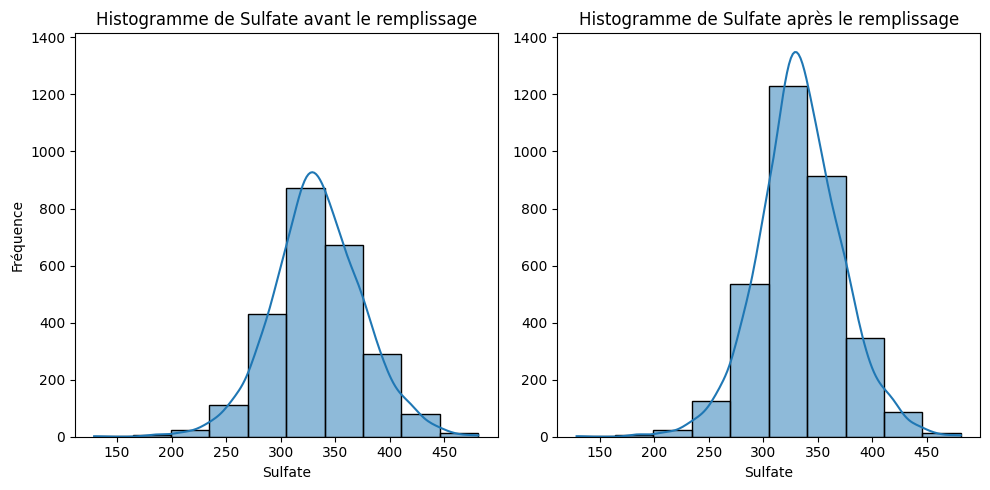

In [171]:
import matplotlib.pyplot as plt
import seaborn as sns
# Créer une figure avec deux sous-graphiques côte à côte
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5), sharex=True, sharey=True)  # 1 ligne, 2 colonnes

# Tracer le premier histogramme sur le premier sous-graphique
sns.histplot(dataset['Sulfate'], bins=10, ax=ax1,kde='true')
ax1.set_xlabel('Sulfate')
ax1.set_ylabel('Fréquence')
ax1.set_title('Histogramme de Sulfate avant le remplissage')

# Tracer le deuxième histogramme sur le deuxième sous-graphique
sns.histplot(ds['Sulfate'], bins=10, ax=ax2,kde='true')
ax2.set_xlabel('Sulfate')
ax2.set_ylabel('Fréquence')
ax2.set_title('Histogramme de Sulfate après le remplissage')

# Répéter la graduation pour les ordonnées sur la deuxième figure
ax2.tick_params(axis='y', labelleft=True)

# Ajuster l'espacement entre les sous-graphiques
plt.tight_layout()

# Afficher la figure
plt.show()

7.7 KNN

In [172]:
from sklearn.impute import KNNImputer
ds_knn = dataset.copy()
numeric_cols = ds_knn.select_dtypes(include=['number']).columns
imputer = KNNImputer(n_neighbors=5)
ds_knn[numeric_cols] = imputer.fit_transform(ds_knn[numeric_cols])
ds_knn

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,7.156857,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0.0
1,3.716080,129.422921,18630.057858,6.635246,336.094350,592.885359,15.180013,56.329076,4.500656,0.0
2,8.099124,224.236259,19909.541732,9.275884,330.449166,418.606213,16.868637,66.420093,3.055934,0.0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0.0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0.0
...,...,...,...,...,...,...,...,...,...,...
3271,4.668102,193.681735,47580.991603,7.166639,359.948574,526.424171,13.894419,66.687695,4.435821,1.0
3272,7.808856,193.553212,17329.802160,8.061362,364.091541,392.449580,19.903225,64.327280,2.798243,1.0
3273,9.419510,175.762646,33155.578218,7.350233,327.357588,432.044783,11.039070,69.845400,3.298875,1.0
3274,5.126763,230.603758,11983.869376,6.303357,325.952434,402.883113,11.168946,77.488213,4.708658,1.0


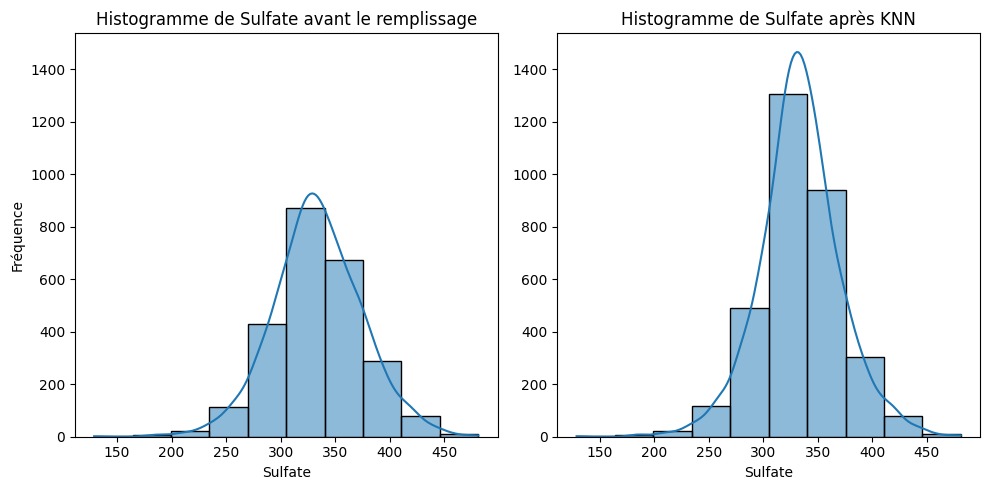

In [173]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5), sharex=True, sharey=True)

# Avant le remplissage
sns.histplot(dataset['Sulfate'], bins=10, ax=ax1, kde=True)
ax1.set_xlabel('Sulfate')
ax1.set_ylabel('Fréquence')
ax1.set_title('Histogramme de Sulfate avant le remplissage')

# Après le remplissage par KNN
sns.histplot(ds_knn['Sulfate'], bins=10, ax=ax2, kde=True)
ax2.set_xlabel('Sulfate')
ax2.set_ylabel('Fréquence')
ax2.set_title('Histogramme de Sulfate après KNN')
ax2.tick_params(axis='y', labelleft=True)

plt.tight_layout()
plt.show()

8. Comparaison des méthodes

In [174]:
s = dataset['Sulfate']

methodes = {
    'Original (sans NaN)': s.dropna(),
    'Moyenne': s.fillna(s.mean()),
    'Médiane': s.fillna(s.median()),
    'Mode': s.fillna(s.mode()[0]),
    'Constante (100)': s.fillna(100),
    'bfill': s.bfill(),
    'ffill': s.ffill(),
    'Interpolation': s.interpolate(method='linear'),
    'KNN': ds_knn['Sulfate'],
}

tableau = pds.DataFrame({
    nom: {'Nb valeurs': v.count(), 'Moyenne': v.mean(), 'Médiane': v.median(),
          'Écart-type': v.std(), 'Skewness': v.skew()}
    for nom, v in methodes.items()
}).T.round(2)

tableau

,Nb valeurs,Moyenne,Médiane,Écart-type,Skewness
Original (sans NaN),2495.0,333.78,333.07,41.42,-0.04
Moyenne,3276.0,333.78,333.78,36.14,-0.04
Médiane,3276.0,333.61,333.07,36.14,-0.03
Mode,3276.0,284.96,318.66,94.46,-0.74
Constante (100),3276.0,278.04,318.66,105.98,-0.84
bfill,3272.0,333.50,332.96,41.07,-0.07
ffill,3276.0,333.95,333.08,41.26,-0.01
Interpolation,3276.0,333.74,332.96,38.87,-0.03
KNN,3276.0,333.61,333.26,37.45,-0.03


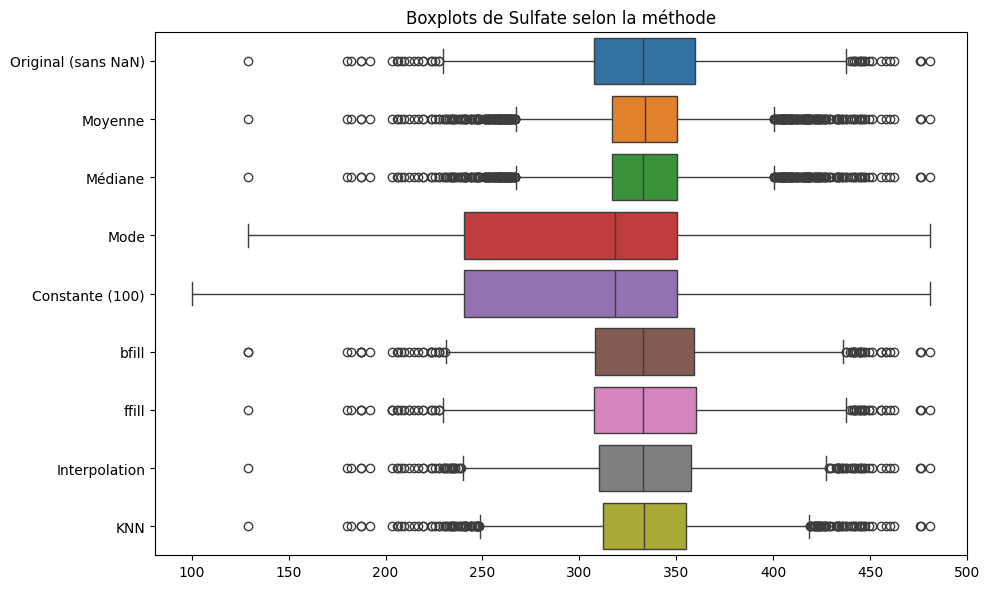

In [175]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=pds.DataFrame(methodes), orient='h')
plt.title('Boxplots de Sulfate selon la méthode')
plt.tight_layout()
plt.show()